# Heart Disease Prediction — Step-by-step walkthrough
**Machine Learning Mini Project**

This notebook walks through the whole workflow one step at a time: loading the UCI Heart Disease data, checking missing values, cleaning, encoding and scaling, training Logistic Regression (baseline), Random Forest and XGBoost, and comparing them on more than accuracy.

The same code is used by `train.py` (to save the models) and `app.py` (the Streamlit app).

In [1]:
import sys, warnings
sys.path.append("..")          # so we can import the project's src/ package
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src import config
from src.data import load_raw_data, missing_value_report, clean_data, split_features_target
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Load the data
The file has 920 patients from four hospitals. `num` is the diagnosis: 0 = no heart disease, 1–4 = heart disease of increasing severity.

In [2]:
raw = load_raw_data()
print(raw.shape)
raw.head()

(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
raw["dataset"].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

## 2. Check missing values

In [4]:
report = missing_value_report(raw)
report[report["missing_count"] > 0]

,missing_count,missing_percent
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


Some missing values are hidden: a cholesterol or blood pressure of **0** is impossible, so those zeros are really missing too.

In [5]:
print("Cholesterol = 0:", (raw["chol"] == 0).sum(), "patients")
print("Blood pressure = 0:", (raw["trestbps"] == 0).sum(), "patients")
raw.loc[raw["chol"] == 0, "dataset"].value_counts()

Cholesterol = 0: 172 patients
Blood pressure = 0: 1 patients


dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64

## 3. Clean the data
Rules applied in `src/data.py`:
1. Zeros in cholesterol / blood pressure → missing.
2. Columns more than 50% empty are dropped (`ca`, `thal`).
3. `id` and the hospital name are not used as inputs.
4. `num > 0` becomes the target `1` (disease present).

In [6]:
df = clean_data(raw)
X, y = split_features_target(df)
print("Clean shape:", df.shape)
df.head()

  - chol: 172 zero values treated as missing
  - trestbps: 1 zero values treated as missing
  - dropping 'ca' (66% missing)
  - dropping 'thal' (53% missing)
  - removed 2 duplicate rows
Clean shape: (918, 12)


,age,trestbps,chol,thalch,oldpeak,sex,cp,fbs,restecg,exang,slope,target
0,63,145.0,233.0,150.0,2.3,Male,typical angina,yes,lv hypertrophy,no,downsloping,0
1,67,160.0,286.0,108.0,1.5,Male,asymptomatic,no,lv hypertrophy,yes,flat,1
2,67,120.0,229.0,129.0,2.6,Male,asymptomatic,no,lv hypertrophy,yes,flat,1
3,37,130.0,250.0,187.0,3.5,Male,non-anginal,no,normal,no,downsloping,0
4,41,130.0,204.0,172.0,1.4,Female,atypical angina,no,lv hypertrophy,no,upsloping,0


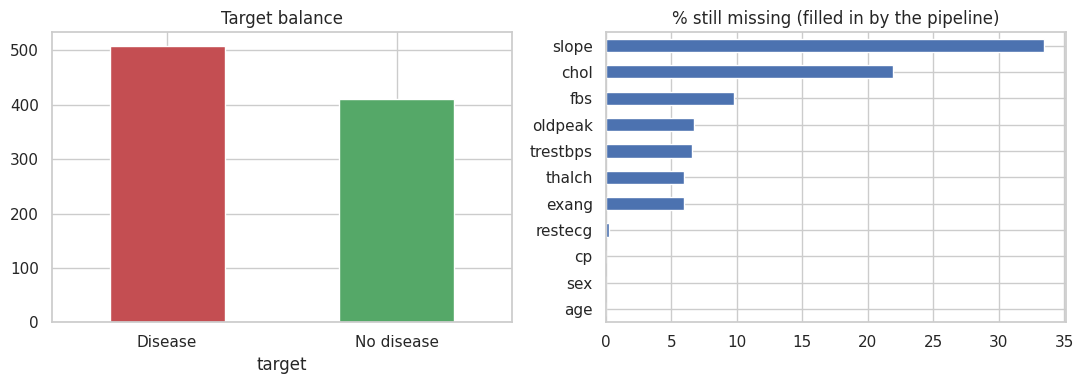

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y.map({0: "No disease", 1: "Disease"}).value_counts().plot.bar(ax=ax[0], color=["#C44E52", "#55A868"], rot=0)
ax[0].set_title("Target balance")
X.isna().mean().mul(100).sort_values().plot.barh(ax=ax[1], color="#4C72B0")
ax[1].set_title("% still missing (filled in by the pipeline)")
plt.tight_layout(); plt.show()

## 4. A quick look at the data

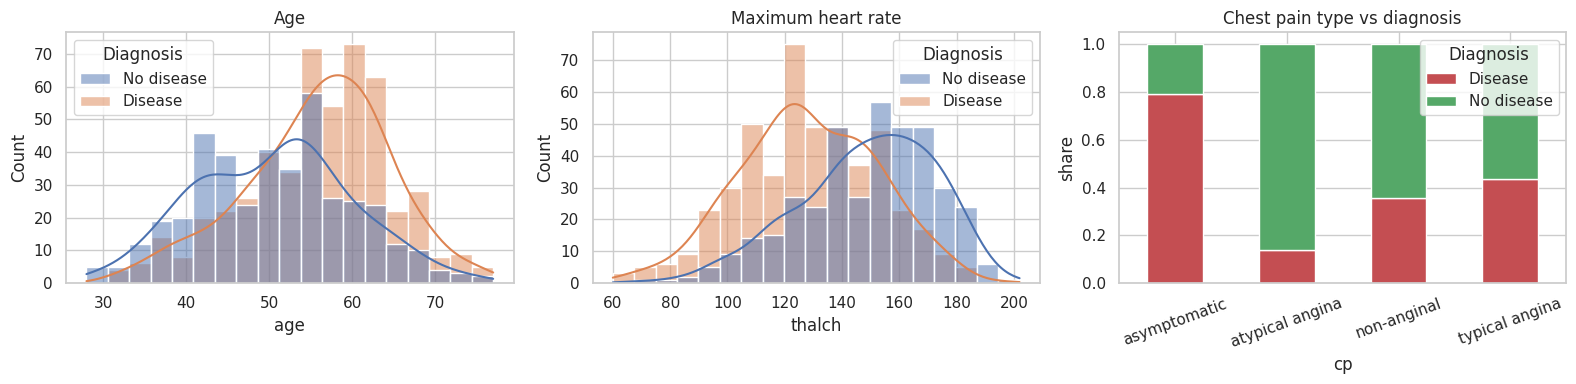

In [8]:
plot_df = df.assign(Diagnosis=df["target"].map({0: "No disease", 1: "Disease"}))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=plot_df, x="age", hue="Diagnosis", kde=True, ax=axes[0]); axes[0].set_title("Age")
sns.histplot(data=plot_df, x="thalch", hue="Diagnosis", kde=True, ax=axes[1]); axes[1].set_title("Maximum heart rate")
pd.crosstab(plot_df["cp"], plot_df["Diagnosis"], normalize="index").plot.bar(stacked=True, ax=axes[2], rot=20,
                                                                          color=["#C44E52", "#55A868"])
axes[2].set_title("Chest pain type vs diagnosis"); axes[2].set_ylabel("share")
plt.tight_layout(); plt.show()

Patients with **no chest pain symptoms (asymptomatic)** are, perhaps surprisingly, the group most likely to have heart disease, and sick patients tend to reach a lower maximum heart rate.

## 5. Preprocessing: encode categories, scale numbers
Both steps live inside a scikit-learn `Pipeline`, so they are learnt from the training data only.

In [9]:
from sklearn.model_selection import train_test_split
from src.preprocessing import build_preprocessor

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.RANDOM_STATE)
print(f"Train: {len(X_train)}  Test: {len(X_test)}")

pre = build_preprocessor().fit(X_train)
encoded = pd.DataFrame(pre.transform(X_train), columns=pre.get_feature_names_out())
print("Columns after one-hot encoding:", encoded.shape[1])
encoded.head().round(2)

Train: 734  Test: 184
Columns after one-hot encoding: 21


,num__age,num__trestbps,num__chol,num__thalch,num__oldpeak,cat__sex_Female,cat__sex_Male,cat__cp_asymptomatic,cat__cp_atypical angina,cat__cp_non-anginal,cat__cp_typical angina,cat__fbs_no,cat__fbs_yes,cat__restecg_lv hypertrophy,cat__restecg_normal,cat__restecg_st-t abnormality,cat__exang_no,cat__exang_yes,cat__slope_downsloping,cat__slope_flat,cat__slope_upsloping
0,-0.28,-0.68,-0.11,-0.43,0.61,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-1.35,-0.68,0.91,1.28,-0.81,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.69,0.99,0.22,0.76,1.64,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.05,-0.40,-0.55,0.09,-0.81,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.48,-1.79,-0.22,0.72,-0.71,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


## 6. Train the three models
Each model is tuned with 5-fold cross-validation. Logistic Regression is the baseline.

In [10]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from src.models import get_model_specs, build_pipeline
from src.evaluate import compute_metrics

cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fitted, rows = {}, []
for key, (estimator, grid) in get_model_specs().items():
    search = GridSearchCV(build_pipeline(estimator), grid, cv=cv, scoring=scoring, refit="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    fitted[key] = search.best_estimator_
    prob = search.best_estimator_.predict_proba(X_test)[:, 1]
    m = compute_metrics(y_test, (prob >= 0.5).astype(int), prob)
    m["cv_f1"] = search.cv_results_["mean_test_f1"][search.best_index_]
    rows.append({"model": config.MODEL_DISPLAY_NAMES[key], **m})
    print(f"{config.MODEL_DISPLAY_NAMES[key]:32s} best settings: {search.best_params_}")

Logistic Regression (baseline)   best settings: {'model__C': 0.1}


Random Forest                    best settings: {'model__max_depth': 4, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}


XGBoost                          best settings: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 0.8}


## 7. Compare — not just accuracy

In [11]:
results = pd.DataFrame(rows).set_index("model")
results[["accuracy", "precision", "recall", "specificity", "f1", "roc_auc",
         "false_negatives", "false_positives", "cv_f1"]].round(3)

,accuracy,precision,recall,specificity,f1,roc_auc,false_negatives,false_positives,cv_f1
model,,,,,,,,,
Logistic Regression (baseline),0.799,0.804,0.843,0.744,0.823,0.888,16,21,0.822
Random Forest,0.799,0.788,0.873,0.707,0.828,0.899,13,24,0.828
XGBoost,0.815,0.815,0.863,0.756,0.838,0.900,14,20,0.815


**How to read this:**
- **Recall** is the key number for a screening tool: it is the share of sick patients the model catches. Every *false negative* is a sick patient sent home.
- **Precision** tells us how many of the flagged patients were really sick (the rest are false alarms).
- **F1** balances the two, and **ROC-AUC** measures ranking quality regardless of the 50% cut-off.

The final model is chosen on the **cross-validated F1** (training data only), so the test set stays an honest final check.

## 8. Charts saved by `train.py`
(Run `python train.py` from the project folder first to create them.)

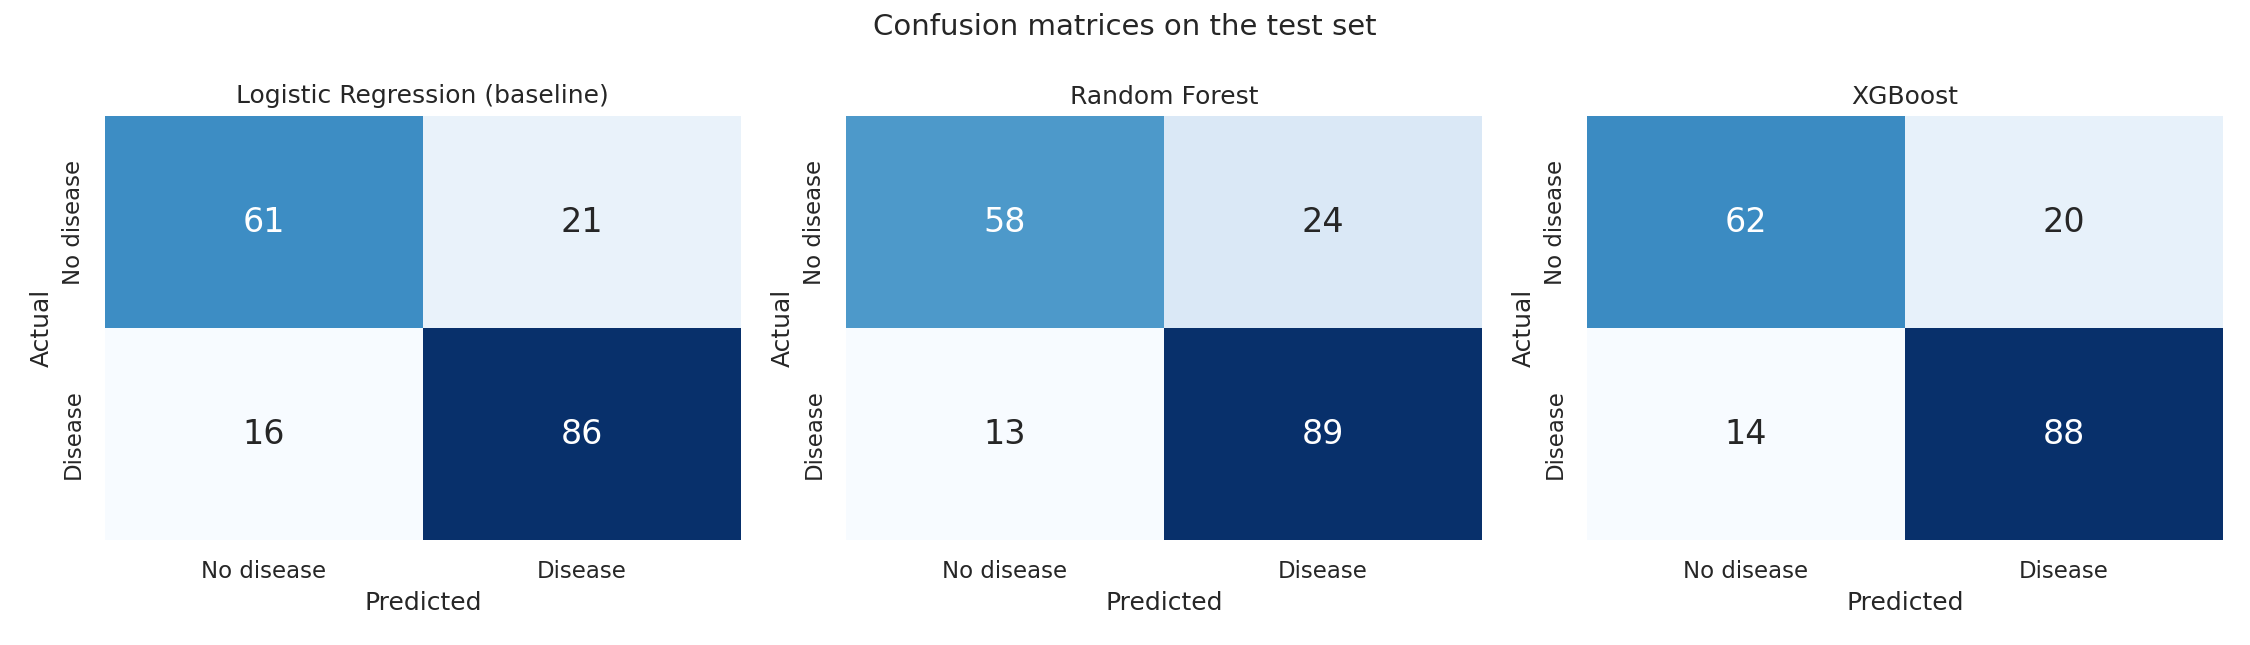

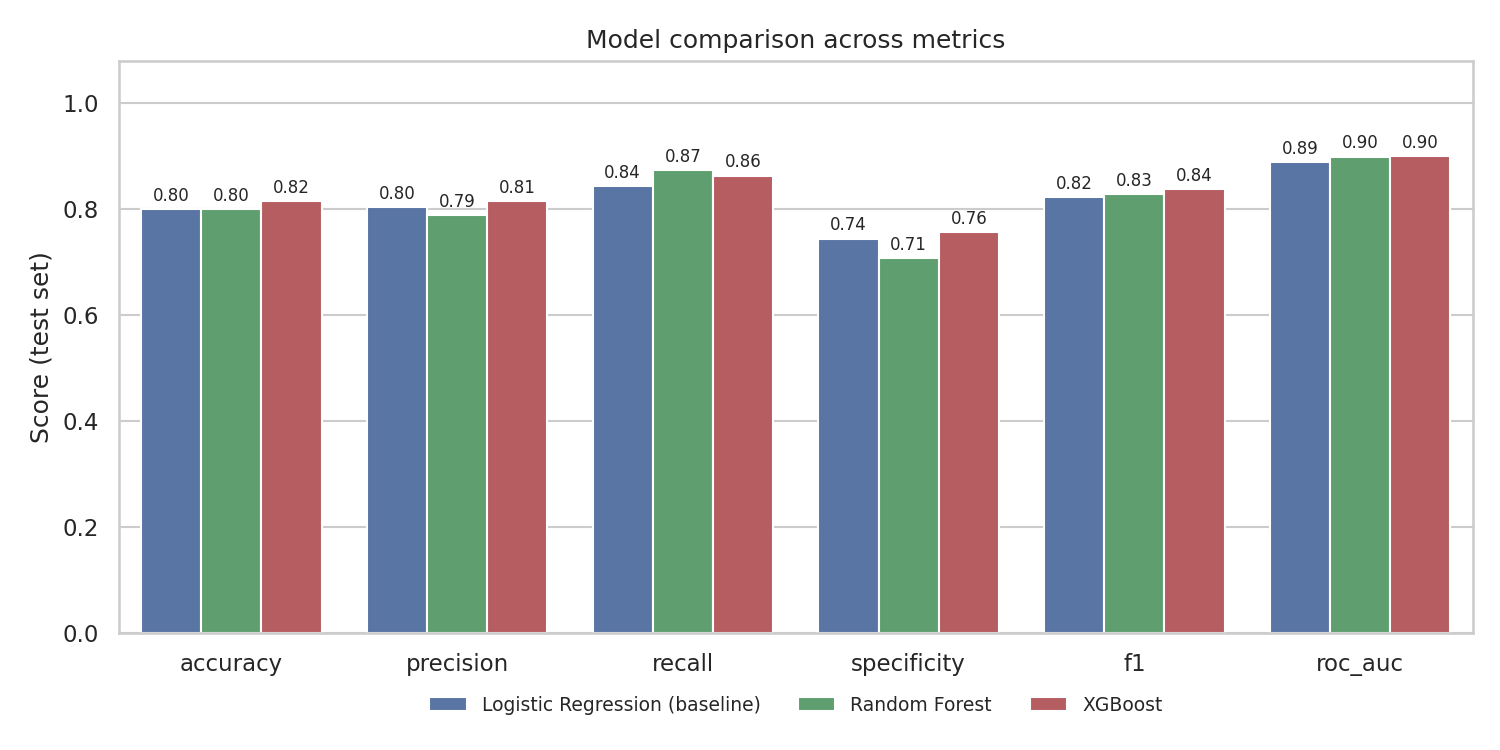

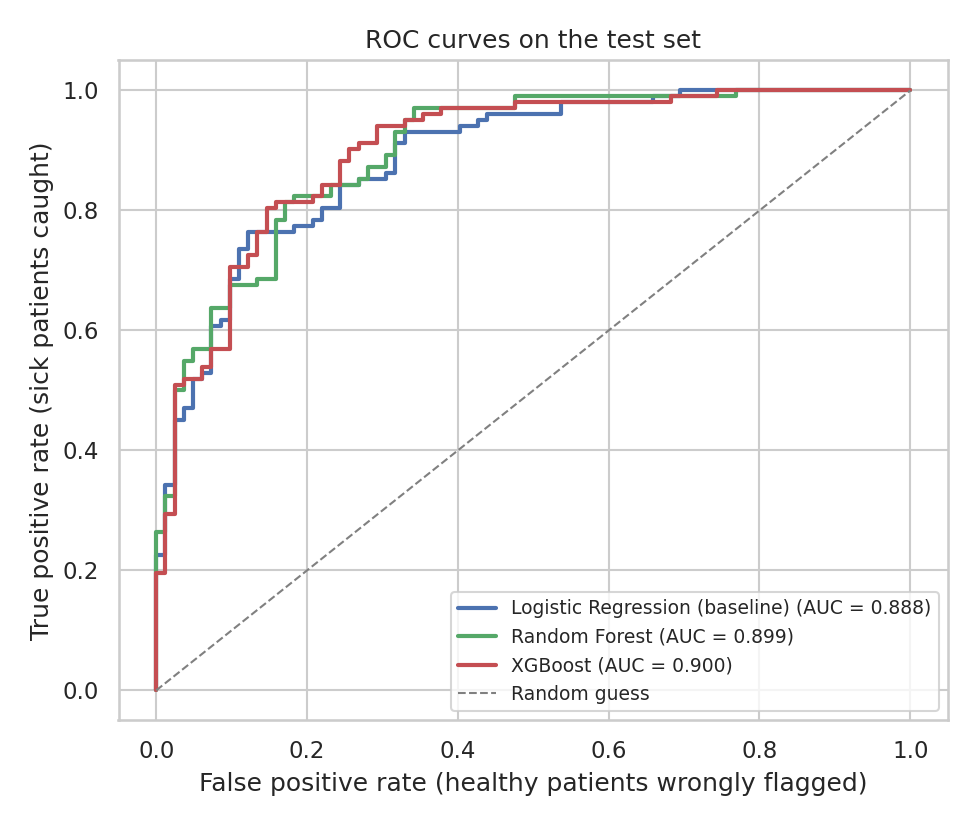

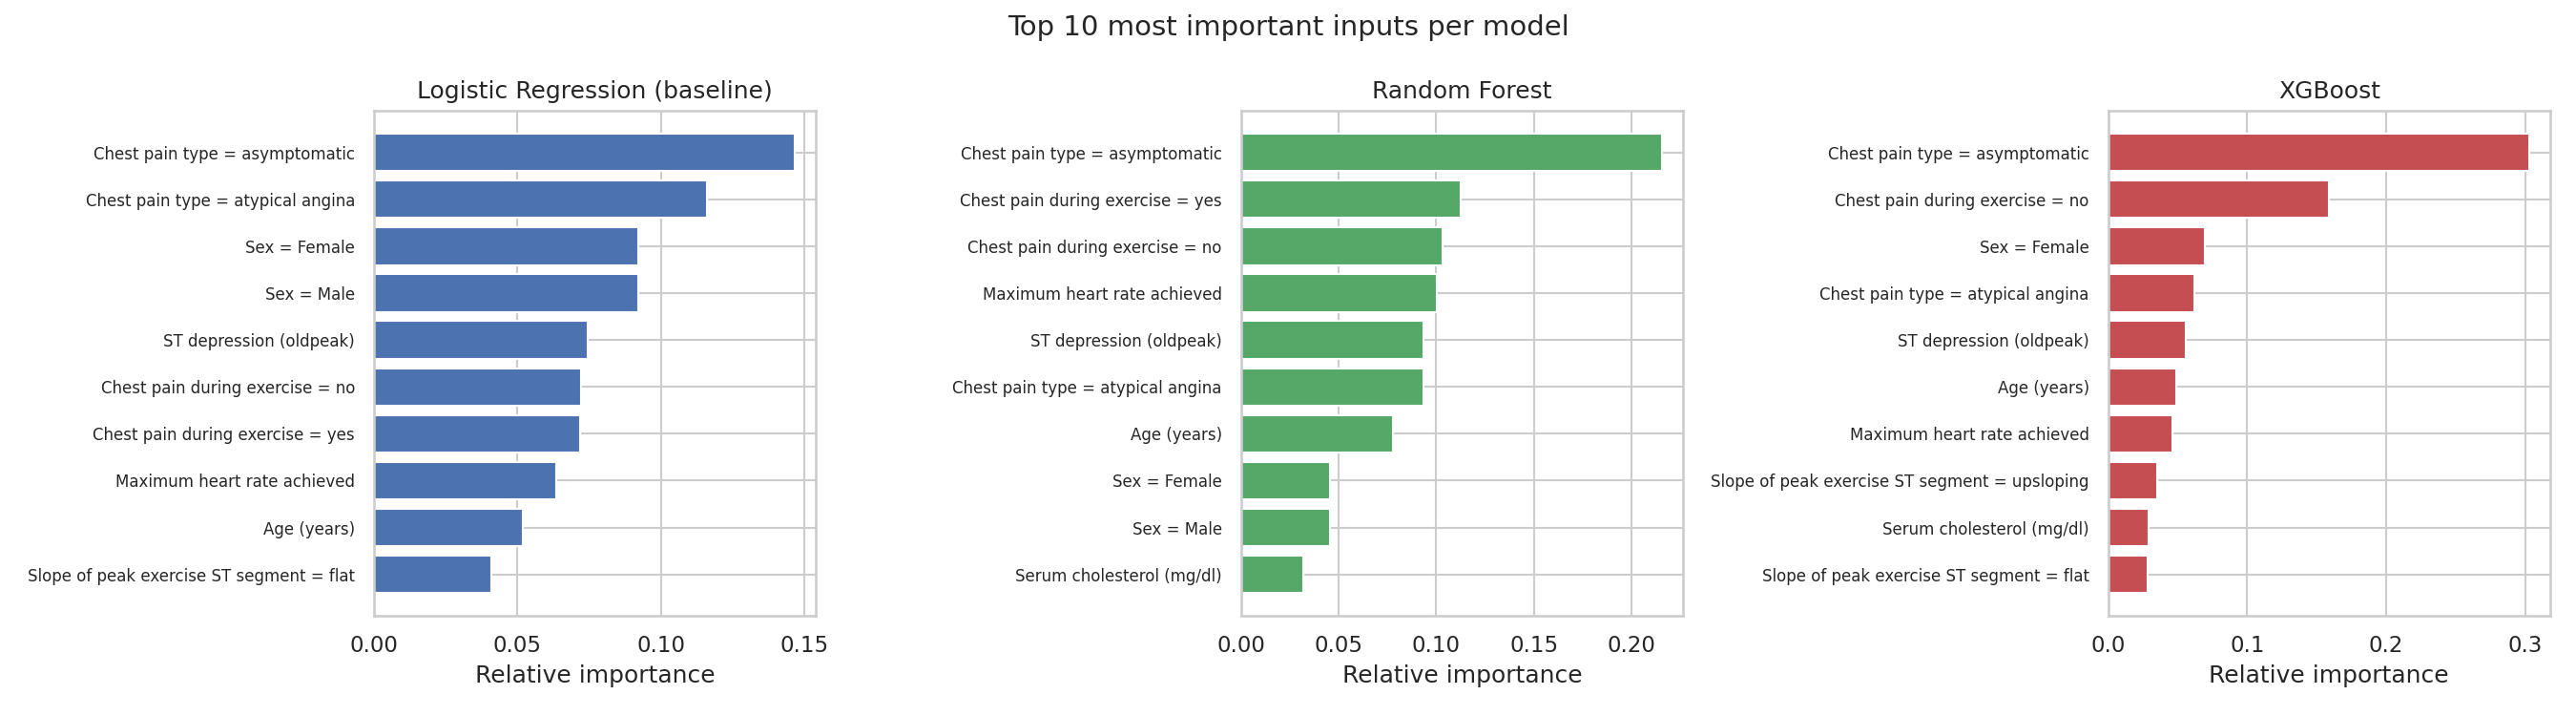

In [12]:
for name in ["confusion_matrices.png", "metric_comparison.png", "roc_curves.png", "feature_importance.png"]:
    path = config.REPORTS_DIR / name
    if path.exists():
        display(Image(filename=str(path)))

## 9. Try a single patient

In [13]:
import joblib
best = joblib.load(config.MODELS_DIR / "best_model.joblib")
patient = pd.DataFrame([{
    "age": 63, "sex": "Male", "cp": "asymptomatic", "trestbps": 145, "chol": 233,
    "fbs": "no", "restecg": "lv hypertrophy", "thalch": 115, "exang": "yes",
    "oldpeak": 2.3, "slope": "flat",
}])
p = best.predict_proba(patient)[0, 1]
print(f"Estimated chance of heart disease: {p:.0%}")

Estimated chance of heart disease: 91%
